# Kriging Approximation of PDE Output With Active Subspaces

__Ryan Howard__ and __Paul Constantine__

<br>

This notebook summarizes the active-subspace kriging approximation of a PDE output from [[1]][R1], and reproduces its elliptic PDE example (§5) with the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later. It runs in Python 3 with numpy, scipy and matplotlib (see the repository's `requirements.txt`), and takes about two minutes.

### Introduction

Complex physical models with uncertain inputs are often subject to _uncertainty quantification_ (UQ) to better understand how the model's output changes when the inputs are varied. Monte Carlo methods are the most straightforward method of UQ, but because they converge slowly and models are becoming increasingly expensive, response surfaces are increasingly employed as an alternative. However, response surface methods suffer the 'curse of dimensionality': the expense of constructing these surfaces increases rapidly as the input space's dimension increases. One way around this curse is to perform sensitivity analysis: identify inputs that are more important in determining output, and construct response surfaces by focusing only on the most important parameters.

*Active Subspaces* is an emerging method of global sensitivity analysis that identifies directions in the input space (not necessarily coordinate directions) along which the output varies much more than in the orthogonal directions. Response surfaces (and other methods) can be more efficiently applied in the subspace defined by the most important directions in the input space. Here, we will describe this method and demonstrate its efficacy by applying it to a high-dimensional elliptic PDE model.

### Active Subspaces

Consider a scalar-valued, differentiable function $f(\mathbf x)$, $\mathbf x\in \chi\subseteq R^m$, where we assume $\chi$ is centered at the origin, and let $\rho$ be a bounded probability density on $\chi$:

$$
\rho(\mathbf x) > 0,\ \mathbf x\in\chi,\ \ \ \ \ \rho(\mathbf x)=0,\ \mathbf x\not\in\chi.
$$

Active subspace methodology is based on the matrix

$$
\mathbf C = \int\nabla f(\mathbf x)\,\nabla f(\mathbf x)^T\ \rho(\mathbf x)\ d\mathbf x = \mathbf W\Lambda\mathbf W^T,
$$

where $\mathbf W$ is the matrix of eigenvectors and $\Lambda$ is the diagonal matrix of eigenvalues in descending order. The $i^{th}$ eigenvalue quantifies the change of $f$ along the $i^{th}$ eigenvector: $\int(\mathbf w_i^T\ \nabla f(\mathbf x))^2\rho(\mathbf x)\ d\mathbf x = \lambda_i$; if $\lambda_i$ is small, $f$ tends to be relatively constant along $\mathbf w_i$. To define the active subspace, we partition the eigendecomposition as:

$$
\mathbf W = \left[\begin{matrix}\mathbf W_1 & \mathbf W_2\end{matrix}\right],\ \ \Lambda = \left[\begin{matrix}\Lambda_1 & \\ & \Lambda_2\end{matrix}\right],
$$

where $\mathbf W_1$ contains the first $n$ (out of $m$) eigenvectors and $\Lambda_1$ has the first $n$ eigenvalues (this partition will be valid if $\lambda_n > \lambda_{n+1}$). The active subspace is the span of $\mathbf W_1$'s columns; perturbations along these directions tend to change $f$ more than in the orthogonal directions. For any $\mathbf x\in R^m,\ \mathbf x = \mathbf W\mathbf W^T\mathbf x = \mathbf W_1 \mathbf W_1^T \mathbf x + \mathbf W_2\mathbf W_2^T\mathbf x = \mathbf W_1\mathbf y + \mathbf W_2 \mathbf z$. $\mathbf y = \mathbf W_1^T\mathbf x$ are called the active variables and $\mathbf z = \mathbf W_2^T\mathbf x$ the inactive variables. The eigenvalues also quantify the average variation of $f$ with respect to the active and inactive variables: $\int\nabla_{\mathbf y}f(\mathbf x)^T\nabla_{\mathbf y}f(\mathbf x)\ \rho(\mathbf x)\ d\mathbf x = \lambda_1+\cdots+\lambda_n$ and $\int\nabla_{\mathbf z}f(\mathbf x)^T\nabla_{\mathbf z}f(\mathbf x)\ \rho(\mathbf x)\ d\mathbf x = \lambda_{n+1}+\cdots+\lambda_m$, where $\nabla_{\mathbf y}f(\mathbf x)$ and $\nabla_{\mathbf z}f(\mathbf x)$ are gradients of $f$ with respect to the active and inactive variables. The distribution $\rho(\mathbf x)$ can be written as a joint density of $\mathbf y$ and $\mathbf z$: $\rho(\mathbf x) = \rho(\mathbf W_1\mathbf y + \mathbf W_2 \mathbf z) = \rho(\mathbf y, \mathbf z)$ (if $\rho$ is standard Gaussian, marginal and conditional densities of $\mathbf y$ and $\mathbf z$ will also be standard Gaussian).

If $\lambda_{n+1},\dots,\lambda_m$ are small, we can approximate $f$ as

$$
f(\mathbf x)\approx G(\mathbf y) = \int f(\mathbf W_1\mathbf y + \mathbf W_2\mathbf z)\ \rho(\mathbf z|\mathbf y)\ d\mathbf z.
$$

$G$ is the conditional average of $f$ given $y$; if $f$ is relatively constant in $\mathbf z$, we expect this to be a good approximation. The MSE of this approximation is bounded by

$$
\int\left(f(\mathbf x) - G(\mathbf W_1^T\mathbf x)\right)^2\ \rho(\mathbf x)\ d\mathbf x \leq C_1(\lambda_{n+1} + \cdots + \lambda_m),
$$

where $C_1$ is a constant that depends only on $\chi$ and $\rho$. $G$ is difficult to compute, so we can use simple Monte Carlo integration to approximate it:

$$
G(\mathbf y) \approx \hat G(\mathbf y) = \frac 1 N\sum_{i=1}^N f(\mathbf W_1\mathbf y + \mathbf W_2\mathbf z_i),
$$

where $\{\mathbf z_i\}_{i=1}^N$ are drawn independently from $\rho(\mathbf z|\mathbf y)$. The error bound on the resulting approximation is

$$
\int\left(f(\mathbf x) - \hat G(\mathbf W_1^T\mathbf x)\right)^2\ \rho(\mathbf x)\ d\mathbf x \leq C_1\left(1 + \frac 1 N\right)(\lambda_{n+1} + \cdots + \lambda_m).
$$

The advantage to using these approximations is that we can now build a response surface to approximate $f$ in $n<m$ dimensions. Let $\{\mathbf y_k\}_{k=1}^P$ be a design on the space of active variables and let $\hat G_k = \hat G(\mathbf y_k)$. We approximate $f(\mathbf x)\approx \tilde G(\mathbf y) = \mathcal R(\mathbf y;\hat G_1,\dots,\hat G_P)$, where $\mathcal R$ is a response surface trained with $\{\hat G_k\}_{k=1}^P$. If we assume the response surface error is bounded by $\int \left(\hat G(\mathbf y) - \tilde G(\mathbf y)\right)^2\rho(\mathbf y|\mathbf z)\ d\mathbf y \leq C_2\delta\ \forall \mathbf z$, where $\delta$ depends on only $\mathcal R$ and $P$ and $C_2$ depends on $\rho$ and $\chi$, then the total error is bounded by

$$
\int\left(f(\mathbf x) - \tilde G(\mathbf W_1^T\mathbf x)\right)^2\ \rho(\mathbf x)\ d\mathbf x \leq C_1\left(1 + \frac 1 N\right)(\lambda_{n+1} + \cdots + \lambda_m) + C_2\delta.
$$

Of course we can't generally compute the matrix $\mathbf C$ analytically, so we approximate it with simple Monte Carlo: draw $\{\mathbf x_i\}_{i=1}^N$ from $\rho$ and compute $\nabla f(\mathbf x_i)$ for each $i$, then

$$
\mathbf C\approx \hat{\mathbf C} = \frac 1 N\sum_{i=1}^N \nabla f(\mathbf x_i)\ \nabla f(\mathbf x_i)^T = \hat{\mathbf W}\hat\Lambda\hat{\mathbf W}^T.
$$

The estimated active and inactive variables are $\hat{\mathbf y} = \hat{\mathbf W}_1^T\mathbf x$ and $\hat{\mathbf z} = \hat{\mathbf W}_2^T\mathbf x$, respectively. The error in the estimated subspace, $\epsilon = ||\hat{\mathbf W}_1^T\mathbf W_2||$ is inversely proportional to $\lambda_{n} - \lambda_{n+1}$, and we can define our approximation as

$$
f(\mathbf x) \approx G_\epsilon(\hat{\mathbf W}_1^T\mathbf x) = \int f(\hat{\mathbf W}_1\hat{\mathbf y} + \hat{\mathbf W}_2\hat{\mathbf z}) \rho(\hat{\mathbf z}|\hat{\mathbf y})d\hat{\mathbf z}
$$

with error bound

$$
\int\left(f(\mathbf x) - G_\epsilon(\hat{\mathbf W}_1^T\mathbf x)\right)^2\ \rho(\mathbf x)\ d\mathbf x \leq C_1\left(\epsilon(\lambda_{1} + \cdots + \lambda_n)^{1/2} + (\lambda_{n+1} + \cdots + \lambda_m)^{1/2}\right)^2.
$$

We can approximate $G_\epsilon$ using simple Monte Carlo in the same way we approximate $G$:

$$
G_\epsilon(\hat{\mathbf y})\approx \hat{G}_\epsilon(\hat{\mathbf y}) = \frac 1 N\sum_{i=1}^N f(\hat{\mathbf W}_1\hat{\mathbf y} + \hat{\mathbf W}_2\hat{\mathbf z}_i),
$$

which has error bound

$$
\int\left(f(\mathbf x) - \hat G_\epsilon(\hat{\mathbf W}_1^T\mathbf x)\right)^2\ \rho(\mathbf x)\ d\mathbf x \leq C_1\left(1+\frac 1 N\right)\left(\epsilon(\lambda_{1} + \cdots + \lambda_n)^{1/2} + (\lambda_{n+1} + \cdots + \lambda_m)^{1/2}\right)^2.
$$

Lastly, we can construct a response surface approximation in the active subspace by choosing a design $\{\hat{\mathbf y}_k\}_{k=1}^P$, evaluating $\hat G_{\epsilon,k} = \hat G_\epsilon (\hat{\mathbf y}_k),\ k=1,\dots,P$, and approximating $\hat G_\epsilon(\hat{\mathbf y})\approx \tilde G_\epsilon(\hat{\mathbf y}) = \mathcal R(\hat{\mathbf y};\hat G_{\epsilon,1},\dots,\hat G_{\epsilon,P})$, where $\mathcal R$ is a response surface trained with the points $\hat G_{\epsilon,1},\dots,\hat G_{\epsilon,P}$. This last layer of approximation has error bounded by

$$
\int\left(f(\mathbf x) - \tilde G_\epsilon(\hat{\mathbf W}_1^T\mathbf x)\right)^2\ \rho(\mathbf x)\ d\mathbf x \leq C_1\left(1+\frac 1 N\right)\left(\epsilon(\lambda_{1} + \cdots + \lambda_n)^{1/2} + (\lambda_{n+1} + \cdots + \lambda_m)^{1/2}\right)^2 + C_2\delta.
$$

In summary, we have a function, $f(\mathbf x)$, that we'd like to approximate, and we do this in several layers: a low-dimensional conditional average, $G(\mathbf y)$; an approximated conditional average, $\hat G(\mathbf y)$; a response surface on this approximation, $\tilde G(\mathbf y)$; and versions of these using the _approximated_ active subspace: $G_\epsilon(\mathbf y),\ \hat G_{\epsilon}(\mathbf y)$, and $\tilde G_\epsilon(\mathbf y)$.

### Kriging Surfaces

We'll now describe a heuristic process for constructing a kriging approximation of $f$ on the active subspace. For simplicity, we'll assume we have an exact computation of $\mathbf W$ and $\Lambda$. First, we need to choose the design on the active subspace, and to this end, we focus on two choices of $\chi$ and $\rho$: standard Gaussian on $R^m$ and uniform density on the hypercube $\chi = [-1,1]^m$. In the Gaussian case, the density $\rho(\mathbf y)$ is also standard Gaussian and we choose the design as a simple tensor product, each univariate design covering three standard deviations (e.g., a design on $R^2$ with 3 points per dimension would be $\{-3, 0, 3\}\times \{-3, 0, 3\}$). In the uniform case, the marginal density will be non-uniform and the active subspace's domain will be a zonotope on $R^n$; algorithms can be used to determine the zonotope's vertices and these can be given to mesh generators to compute a design.

For each $\mathbf y_k$ in our design, we choose one $\mathbf x_k$ to compute $\hat G_k = f(\mathbf x_k)$; in the Gaussian case, we can choose $\mathbf x_k = \mathbf W_1 \mathbf y_k$ and in the uniform case, we must choose $\mathbf x_k$ such that $\mathbf y_k = \mathbf W_1^T\mathbf x_k$ and $\mathbf x_k\in[-1,1]^m$, which can be found with linear programming. The set $\{(\mathbf y_k, \hat G_k)\}$ is used to train the kriging surface.

Since there is noise in using $\hat G$ to estimate $G$, we want to incorporate this noise into our kriging model. To this end, we choose the covariance of the training data to be

$$
Cov\left[\tilde G(\mathbf y_{k_1}), \tilde G(\mathbf y_{k_2})\right] = K(\mathbf y_{k_1}, \mathbf y_{k_2}) + \eta^2\delta(k_1, k_2),
$$

where $\delta(k_1, k_2) = 1$ if $k_1=k_2$ and 0 otherwise, and

$$
K(\mathbf y_{k_1}, \mathbf y_{k_2}) = \exp\left(-\sum_{i=1}^n\frac{(y_{k_1,i} - y_{k_2,i})^2}{2l_i^2}\right).
$$

We choose a quadratic mean term, and are left to estimate the correlation lengths $l_i$ and the noise parameter $\eta^2$. After we have these estimates, the coefficients of the quadratic mean and the linear combination of training data are computed as usual. We could use maximum likelihood methods to estimate $l_i$ and $\eta^2$, but we choose to use active subspace results to inform our estimates. To this end, first we approximate the directional derivative of $f$ along $\mathbf w_i$ using a finite difference: $\nabla f^T\mathbf w_i\approx\frac 1 \delta (f(\mathbf x + \delta \mathbf w_i)-f(\mathbf x))$, and decompose $f(\mathbf x) = f_0 + f'(\mathbf x)$, where $f_0 = E[f]$ (we use $E[f]$ and $V[f]$ as shorthands to denote integrals of $f$). Now,

\begin{align*}
\lambda_i &= E[(\nabla f^T\mathbf w_i)^2]\\
&\approx \frac{1}{\delta^2}E\left[(f(\mathbf x + \delta\mathbf w_i) - f(\mathbf x))^2\right]\\
&= \frac{1}{\delta^2}E\left[(f'(\mathbf x + \delta\mathbf w_i) - f'(\mathbf x))^2\right]\\
&=\frac{2}{\delta^2}\left(\sigma^2-Cov[f'(\mathbf x + \delta\mathbf w_i), f'(\mathbf x)]\right),
\end{align*}

where $\sigma^2 = V[f]$. Rearranged: $Corr[f'(\mathbf x + \delta\mathbf w_i), f'(\mathbf x)] = 1 - \frac{\lambda_i\delta^2}{2\sigma^2}$. A univariate squared exponential correlation function with length parameter $l$ has a Taylor expansion of $\exp(-\frac{\delta^2}{2l^2}) = 1 - \frac{\delta^2}{2l^2} + \cdots$; comparing these, we can estimate $l_i$ as $l_i^2 = \frac{\sigma^2}{\lambda_i}$.

We know from the active subspace analysis that $\sigma^2 = V(f)\leq C_1(\lambda_{1}+\cdots+\lambda_m)$. Because this is a loose bound, we assume that there is an $\alpha\leq C_1$ such that $\sigma^2 = \alpha(\lambda_1+\cdots+\lambda_m)$. If $\chi = R^m$ and $\rho$ is standard Gaussian, $C_1 = 1$ (the Gaussian Poincaré inequality). If $\chi = [-1,1]^m$ and $\rho$ is uniform, $C_1 = 4/\pi^2$ in every dimension; [[1]][R1] prints the looser bound $2\sqrt m/\pi$. To find a lower bound on $\alpha$, we use the biased estimate of variance: $\hat\sigma^2 = \frac 1 M\sum_{j=1}^M(f_j-\hat f_0)^2$, where $\hat f_0$ is the empirical mean of $\{f_j\}$; we expect the bias to be significant enough that $\hat \sigma^2\leq\alpha(\lambda_1+\cdots+\lambda_m)$, so that $\alpha$ is bounded by

$$
\frac{\hat\sigma^2}{\lambda_1+\cdots+\lambda_m}\leq\alpha\leq C_1.
$$

$\alpha$ can now be treated as a hyperparameter and estimated using maximum likelihood. Once we have an estimate for $\alpha$, we set $\sigma^2 = \alpha(\lambda_1+\cdots+\lambda_m)$ and $\eta^2 = \alpha(\lambda_{n+1}+\cdots+\lambda_m)$.

In active_subspaces v1, `ac.fit_surrogate(..., kind="rbf", f_variance=σ̂²)` implements this heuristic. Its kernel is $\exp(-\sum_i (y_{k_1,i}-y_{k_2,i})^2/\ell_i)$ with $\ell_i = \eta\,(\lambda_1+\cdots+\lambda_m)/\lambda_i$, which is the kernel above with $\eta = 2\alpha$. It searches $\eta$ by maximum likelihood over the interval above (times 2), and differs from [[1]][R1] in two flagged ways: it estimates the amplitude $\sigma^2$ by likelihood instead of tying it to $\alpha$, and its nugget, relative to $\sigma^2$, is $\eta(\lambda_{n+1}+\cdots+\lambda_m)/(\lambda_1+\cdots+\lambda_m)$.

### References:

[[1]][R1] P.G. Constantine, E. Dow, and Q. Wang. _Active subspace methods in theory and practice: applications to kriging surfaces_. SIAM J. Sci. Comput., 36(4):A1500–A1524, 2014. doi:10.1137/130916138

[[2]][R2] P.G. Constantine. _Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies_. SIAM, 2015. doi:10.1137/1.9781611973860

[[3]][R3] P.G. Constantine, C. Kent, and T. Bui-Thanh. _Accelerating Markov chain Monte Carlo with active subspaces_. SIAM J. Sci. Comput., 38(5):A2779–A2805, 2016. doi:10.1137/15M1042127

[R1]: https://doi.org/10.1137/130916138
[R2]: https://doi.org/10.1137/1.9781611973860
[R3]: https://doi.org/10.1137/15M1042127

### Acknowledgments

This material is based upon work supported by the U.S. Department of Energy Office of Science, Office of Advanced Scientific Computing Research, Applied Mathematics program under Award Number DE-SC-0011077.

### Demonstration on an Elliptic PDE

We'll now demonstrate active-subspaces analysis on output derived from an elliptic PDE. First, we describe the model.

Let $u(\mathbf s, \mathbf x)$ satisfy the PDE

$$
-\nabla_{\mathbf s}\cdot(a\nabla_{\mathbf s}u) = 1,\ \ \ \mathbf s\in[0,1]^2.
$$

Homogeneous Dirichlet boundary conditions are used on the left, top, and bottom boundaries of the domain (denote these boundaries by $\Gamma_1$), and a homogeneous Neumann condition is used on the right boundary (denoted by $\Gamma_2$). The log of the coefficients $a(\mathbf s, \mathbf x)$ is given by a truncated Karhunen-Loeve series:

$$
\log(a(\mathbf s, \mathbf x)) = \sum_{i=1}^m x_i\sqrt{\gamma_i}\,\phi_i(\mathbf s),
$$

where $\{x_i\}\sim_{iid} N(0,1)$ and the $\{\phi_i(\mathbf s),\gamma_i\}$ are eigenpairs of the correlation function

$$
\mathcal C(\mathbf s, \mathbf t) = \exp\left(-\frac{\|\mathbf s - \mathbf t\|_1}{2\beta}\right).
$$

We study $\beta=1$ (the long correlation length) and $\beta=.01$ (the short one). The papers write this kernel as $\exp(-\beta^{-1}\|\mathbf s - \mathbf t\|_1)$ ([[1]][R1] eq. (5.3), which also lacks the minus sign; [[2]][R2] eq. (3.80); [[3]][R3] eq. (5.5) with $\beta = 0.02$ for the short field). The eigenpairs shipped with this notebook, `kl-long.npz` and `kl-short.npz`, belong to the kernel with $2\beta$, so that is the field used here. The eigenpairs are those of the discrete covariance matrix on the $100\times 100$ grid of cell centres. The script that generated them is lost, and the files are used as shipped (see `DATA.md`).

We choose $m=100$, so that $\chi = R^{100}$ and $\rho$ is standard Gaussian. The 100 modes carry almost all of the field's variance for $\beta = 1$ but only a small part of it for $\beta = .01$ (printed by the solver check below), which is one reason the short-correlation output is nearly linear in $\mathbf x$. Our scalar quantity of interest is

$$
\frac{1}{|\Gamma_2|}\int_{\Gamma_2}u(\mathbf s,\mathbf x)\,d\mathbf s.
$$

**Discretization.** [[1]][R1] and [[2]][R2] solve the PDE with a MATLAB finite-element code. This notebook uses `pde_model.py`, a different discretization in numpy and scipy: a five-point, vertex-centred finite-volume scheme on a $100\times 100$ grid of cells. The coefficient $a$ is constant on each cell, and its value on a cell face is the average of the two cells next to it. The unknowns are the $99\times 99$ interior vertices. The Neumann condition copies the last column of unknowns onto the right boundary, so it is first-order accurate. The discrete system is

$$
\mathbf A(\mathbf x)\,\mathbf u = \mathbf 1,
$$

with $\mathbf A$ symmetric and positive definite, and the quantity of interest is $f(\mathbf x) = \mathbf c^T\mathbf u(\mathbf x)$. The vector $\mathbf c$ holds trapezoid weights on the column of vertices at $s_1 = 0.99$ (which equals the right boundary) for $s_2 = 0.01,\dots,0.99$, with the two end nodes at half weight; $|\Gamma_2| = 1$.

**Gradients.** For any constant vector $\boldsymbol\lambda$, $f = \mathbf c^T\mathbf u - \boldsymbol\lambda^T(\mathbf A\mathbf u - \mathbf 1)$; differentiating with respect to $x_i$, we find

$$
\frac{\partial f}{\partial x_i} = (\mathbf c^T - \boldsymbol\lambda^T\mathbf A)\frac{\partial \mathbf u}{\partial x_i} - \boldsymbol\lambda^T\frac{\partial \mathbf A}{\partial x_i}\mathbf u.
$$

If $\boldsymbol\lambda$ solves the adjoint problem $\mathbf A^T\boldsymbol\lambda = \mathbf c$, then $\frac{\partial f}{\partial x_i} = - \boldsymbol\lambda^T\frac{\partial \mathbf A}{\partial x_i}\mathbf u$. $\mathbf A$ depends on $\mathbf x$ only through $a = \exp(\sum_i x_i\sqrt{\gamma_i}\phi_i)$, so $\frac{\partial \mathbf A}{\partial x_i}$ follows from $\frac{\partial a}{\partial x_i} = a\sqrt{\gamma_i}\phi_i$. One sparse LU factorization of $\mathbf A$ serves both the forward and the adjoint solve, so `PDESolver.qoi_and_grad` returns $f$ and $\nabla f$ for about the cost of one solve.

The [active_subspaces](https://github.com/paulcon/active_subspaces) library does the analysis below.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
from pde_model import PDESolver

t_start = time.perf_counter()
rng = np.random.default_rng(2014)        # the only source of randomness in this notebook
space = ac.Gaussian.reference(100)       # x ~ N(0, I): physical and normalized inputs coincide

cases = ['long', 'short']
beta = {'long': '1', 'short': '.01'}
solvers = {case: PDESolver(case) for case in cases}

First we draw $M = 300$ samples from the 100-variable standard normal distribution, at which we will compute the values and gradients of the quantity of interest, and an independent set of 500 test points for the comparison at the end.

Before using the solver, we check it at the first sample: the legacy finite-volume residual at the computed solution, the adjoint gradient against central finite differences on four coordinates, and the value at $\mathbf x = 0$, where $a \equiv 1$ and both fields give the same $f$.

In [2]:
X = rng.standard_normal((300, 100))       # gradient samples
X_test = rng.standard_normal((500, 100))  # independent test set

x, h, coords = X[0], 1e-5, [0, 1, 2, 5]
for case, s in solvers.items():
    u, a, _ = s.solve(x)
    q, g = s.qoi_and_grad(x)
    fd = np.array([(s.qoi(x + h*e) - s.qoi(x - h*e)) / (2*h) for e in np.eye(s.m)[coords]])
    print(f'beta = {beta[case]}: max |residual| = {np.abs(s.residual(u, a)).max():.1e}, '
          f'FD vs adjoint relative error <= {np.max(np.abs(fd - g[coords]) / np.abs(g[coords])):.1e}, '
          f'f(0) = {s.qoi(np.zeros(s.m)):.5f}, '
          f'field variance carried by the 100 modes = {(s.B**2).sum() / s.B.shape[0]:.1%}')

beta = 1: max |residual| = 3.0e-12, FD vs adjoint relative error <= 1.1e-08, f(0) = 0.07608, field variance carried by the 100 modes = 99.2%


beta = .01: max |residual| = 4.9e-12, FD vs adjoint relative error <= 6.8e-08, f(0) = 0.07608, field variance carried by the 100 modes = 13.3%


Now we compute the values and gradients at the 300 samples, one solve and one adjoint solve per sample, and the active subspace for both correlation lengths.

Eigenvector signs are arbitrary. v1 makes each eigenvector's largest component positive; we use `ac.orient` to make the first component of the first two eigenvectors positive instead, the 2016 package's rule, so that the figure matches the 2016 notebook.

In [3]:
f, G, sub = {}, {}, {}
for case, s in solvers.items():
    fg = [s.qoi_and_grad(x) for x in X]
    f[case] = np.array([v for v, _ in fg])
    G[case] = np.array([g for _, g in fg])
    sub[case] = ac.orient(ac.active_subspace(space=space, grads=G[case]),
                          by='reference', reference=np.eye(100)[:, [0, 0]], columns=2)
print(f'300 values and gradients for each field: {time.perf_counter() - t_start:.0f} s so far')

300 values and gradients for each field: 13 s so far


[[1]][R1] Table 1 compares the decay of the KL eigenvalues with the decay of the active subspace eigenvalues. Its entries are called normalized singular values, but they are eigenvalue ratios $\lambda_i/\lambda_1$: the KL column for $\beta = 1$ matches the shipped KL eigenvalue ratios, not their square roots. We print the same ratios beside the paper's. The KL ratios for $\beta = 1$ match the paper's, but those for $\beta = .01$ do not, so the paper's short-correlation field may differ from the shipped one (see the note on the kernel above).

In [4]:
paper_table1 = {'KL long': [1, .0978, .0975, .0282, .0280], 'AS long': [1, .0010, .0006, .0005, .0002],
                'KL short': [1, .9946, .9873, .9836, .9774], 'AS short': [1, .0055, .0047, .0046, .0042]}
print(f'{"lambda_i / lambda_1":>22}' + ''.join(f'{i:>9d}' for i in range(1, 6)))
for case, s in solvers.items():
    kl = (s.B**2).sum(axis=0)           # the KL eigenvalues gamma_i (columns of K are orthonormal)
    lam = sub[case].eigenvalues
    for name, r in [('KL', kl[:5] / kl[0]), ('AS', lam[:5] / lam[0])]:
        key = f'{name} {case}'
        print(f'{key + ", beta = " + beta[case]:>22}' + ''.join(f'{v:9.4f}' for v in r))
        print(f'{"paper":>22}' + ''.join(f'{v:9.4f}' for v in paper_table1[key]))

   lambda_i / lambda_1        1        2        3        4        5
     KL long, beta = 1   1.0000   0.0975   0.0975   0.0281   0.0281
                 paper   1.0000   0.0978   0.0975   0.0282   0.0280
     AS long, beta = 1   1.0000   0.0011   0.0006   0.0005   0.0003
                 paper   1.0000   0.0010   0.0006   0.0005   0.0002
  KL short, beta = .01   1.0000   0.9894   0.9894   0.9790   0.9723
                 paper   1.0000   0.9946   0.9873   0.9836   0.9774
  AS short, beta = .01   1.0000   0.0062   0.0054   0.0047   0.0044
                 paper   1.0000   0.0055   0.0047   0.0046   0.0042


Next we plot the first two eigenvectors for each correlation length.

beta = 1: w1[:3] = [ 0.965  0.184 -0.138]
beta = .01: w1[:3] = [0.355 0.128 0.151]


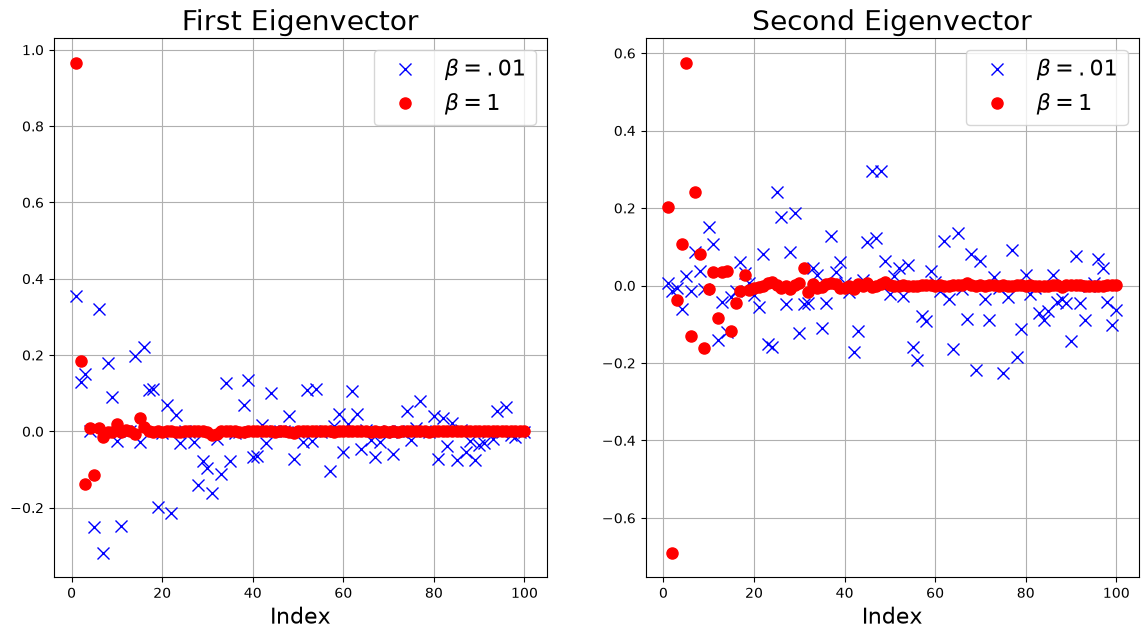

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for j, title in enumerate(['First Eigenvector', 'Second Eigenvector']):
    axes[j].plot(np.arange(1, 101), sub['short'].W[:, j], 'bx', ms=8, label=r'$\beta=.01$')
    axes[j].plot(np.arange(1, 101), sub['long'].W[:, j], 'ro', ms=8, label=r'$\beta=1$')
    axes[j].grid(True)
    axes[j].legend(fontsize=16)
    axes[j].set_xlabel('Index', fontsize=16)
    axes[j].set_title(title, fontsize=20)
for case in cases:
    print(f'beta = {beta[case]}: w1[:3] = {np.round(sub[case].W[:3, 0], 3)}')

Components of the first eigenvector with higher absolute value indicate higher sensitivity to the corresponding parameter. We see the weight in the first eigenvector is more evenly distributed in the short correlation length, which means most of the parameters are important in characterizing output in that case, compared to the long correlation length for which most parameters (those with high indices) are unimportant in characterizing output.

Now we'll construct one-dimensional kriging surfaces for each correlation length on two subspaces: the active subspace, and the coordinate subspace of the input with the largest-magnitude component of the gradient $\nabla f(\mathbf 0)$ at the origin, as in [[1]][R1]. We call the second one "SENS", for local sensitivity analysis. The paper reports $x_1, x_3$ for $\beta = 1$ and $x_6, x_1$ for $\beta = .01$. Our $x_1, x_2$ for $\beta = 1$ differ only within a degenerate KL pair: $\gamma_2 = \gamma_3$, so how the eigensolver rotated $\phi_2$ and $\phi_3$ inside their two-dimensional eigenspace, and therefore which of $x_2, x_3$ has the larger derivative at the origin, depends on the code that computed the KL basis.

In [6]:
sens = {}
for case, s in solvers.items():
    g0 = s.qoi_and_grad(np.zeros(s.m))[1]
    sens[case] = np.argsort(-np.abs(g0))[:2]
    kl = (s.B**2).sum(axis=0)
    print(f'beta = {beta[case]}: SENS coordinates x{sens[case][0] + 1}, x{sens[case][1] + 1}; '
          f'gamma_2 / gamma_3 = {kl[1] / kl[2]:.6f}')

beta = 1: SENS coordinates x1, x2; gamma_2 / gamma_3 = 1.000000
beta = .01: SENS coordinates x1, x6; gamma_2 / gamma_3 = 1.000000


The design on each subspace is the tensor product of $\{-3, -1.5, 0, 1.5, 3\}$ ($P = 5$ points for $n = 1$, $P = 25$ for $n = 2$), mapped to $\mathbf x_k = \mathbf W_1\mathbf y_k$ for the active subspace, and to $\mathbf x$ with the SENS coordinates set and the others zero for SENS. Every surface has a quadratic mean.

- **Active subspace, $\beta = .01$:** the hyperparameter heuristic above, `f_variance` $=\hat\sigma^2$ of the 300 sample values. Here $\hat\sigma^2$ exceeds $C_1(\lambda_1+\cdots+\lambda_m)$, so the interval for $\alpha$ is empty, and v1 warns `accuracy.empty_bounds` and uses its upper end, $\alpha = C_1$. The output is nearly linear, so its variance nearly attains the Poincaré bound, and sampling error pushes it over.
- **Active subspace, $\beta = 1$:** we fix $\ell_1 = 1$, as the 2016 notebook did "to agree with the paper". (The 2016 code set it after training, so its surface did not interpolate its own training data; here the surface is fitted with $\ell_1 = 1$.) With the heuristic interval instead, the likelihood puts $\eta$ at the interval's upper end, and the two-dimensional surface is then less accurate than the SENS one.
- **SENS:** an isotropic length scale chosen by maximum likelihood. [[1]][R1] used the GPML code's maximum likelihood for an isotropic squared-exponential kernel. For $n = 1$ and $\beta = 1$ the likelihood drives the length scale to the bottom of its range, so away from the training points that surface is just its quadratic mean.

In [7]:
y1 = np.array([-3, -1.5, 0, 1.5, 3])
designs = {1: y1[:, None], 2: np.array(np.meshgrid(y1, y1, indexing='ij')).reshape(2, -1).T}


def fit(case, n, subspace, X_train, **kw):
    f_train = np.array([solvers[case].qoi(x) for x in X_train])
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        rs = ac.fit_surrogate(X=X_train, f=f_train, subspace=subspace, kind='rbf', degree=2, **kw)
    for w in caught:
        print(f'beta = {beta[case]}, n = {n}: {getattr(w.message, "code", w.category.__name__)}')
    return rs


def fit_as(case, n):
    sn = ac.with_dimension(sub[case], n)
    if case == 'long':
        lam = sn.eigenvalues
        kw = {'log10_eta': -np.log10(np.abs(lam).sum() / lam[0])}   # ell_1 = 1
    else:
        kw = {'f_variance': f[case].var()}
    return fit(case, n, sn, designs[n] @ sn.W1.T, **kw)


def fit_sens(case, n):
    idx = sens[case][:n]
    X_train = np.zeros((len(designs[n]), 100))
    X_train[:, idx] = designs[n]
    return fit(case, n, ac.subspace_from_basis(np.eye(100)[:, idx], space=space), X_train)


rs_as = {(case, n): fit_as(case, n) for case in cases for n in (1, 2)}
rs_sens = {(case, n): fit_sens(case, n) for case in cases for n in (1, 2)}
for case in cases:
    print(f'beta = {beta[case]}: AS length scales n = 1: {np.round(rs_as[case, 1].length_scales, 3)}, '
          f'n = 2: {np.round(rs_as[case, 2].length_scales, 3)}; SENS length scale n = 1: '
          f'{rs_sens[case, 1].length_scales[0]:.1e}, n = 2: {rs_sens[case, 2].length_scales[0]:.1e}')

beta = .01, n = 1: accuracy.empty_bounds


beta = .01, n = 2: accuracy.empty_bounds


beta = 1: AS length scales n = 1: [1.], n = 2: [  1.   918.69]; SENS length scale n = 1: 1.8e-10, n = 2: 1.0e+01
beta = .01: AS length scales n = 1: [2.093], n = 2: [  2.093 337.603]; SENS length scale n = 1: 1.8e-10, n = 2: 1.0e+01


Now we make plots showing the quantity of interest against the subspace variable (the active variable or the SENS input variable). The 300 samples are the test data, as in [[1]][R1]. If the subspace is of good quality, we expect to see a tight univariate trend with little deviation around it.

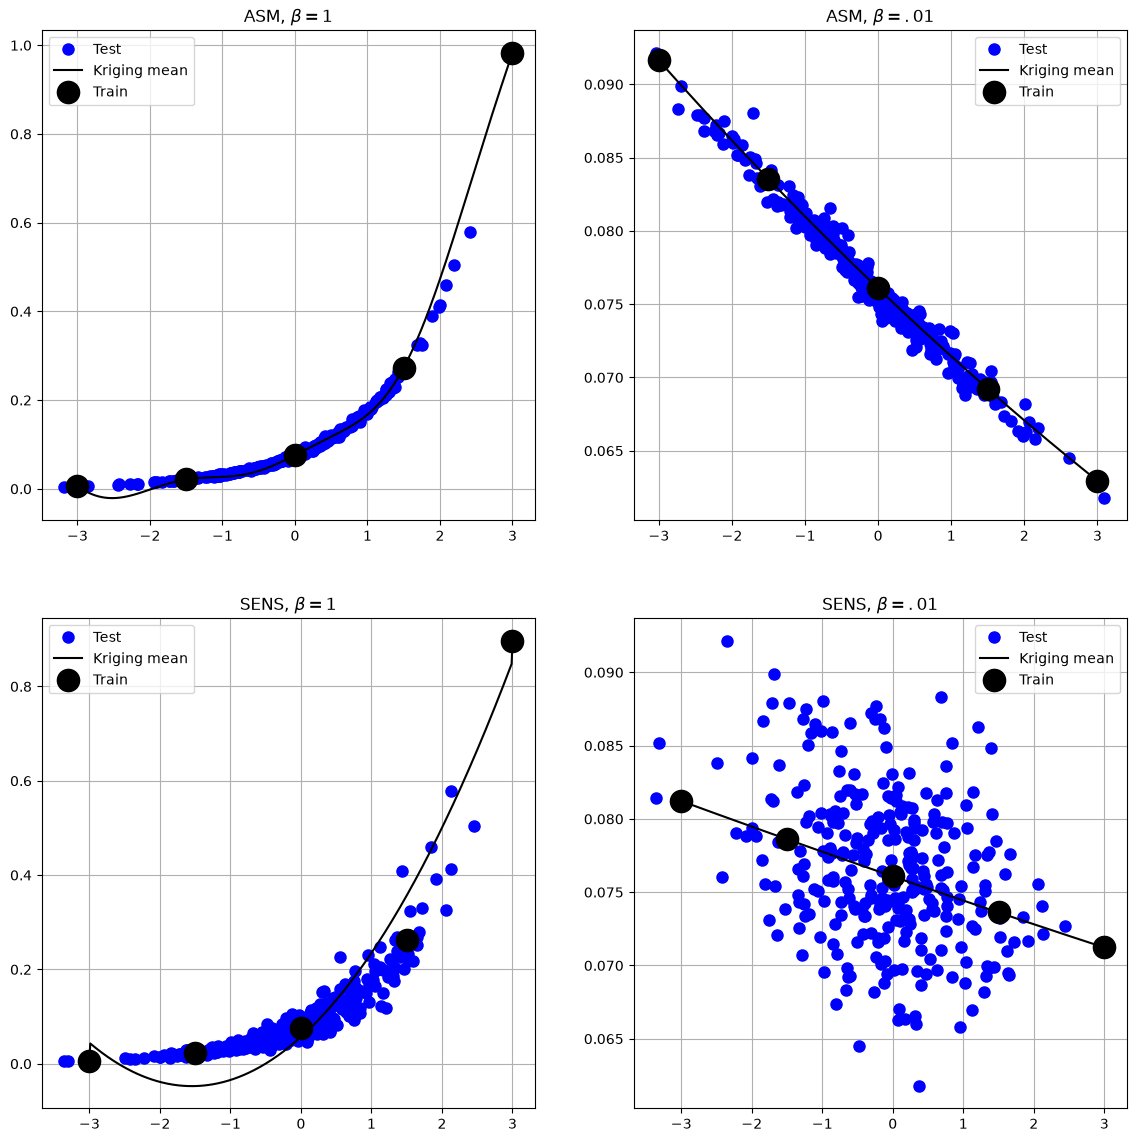

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 14))
y = np.linspace(-3, 3, 500)[:, None]
for col, case in enumerate(cases):
    for row, (label, rs, t) in enumerate([('ASM', rs_as[case, 1], X @ sub[case].W[:, 0]),
                                          ('SENS', rs_sens[case, 1], X[:, sens[case][0]])]):
        ax = axes[row, col]
        ax.plot(t, f[case], 'bo', ms=8, label='Test')
        ax.plot(y, rs.evaluate(y), 'k-', label='Kriging mean')
        ax.plot(rs.Y[:, 0], rs.f, 'ko', ms=16, label='Train')
        ax.grid(True)
        ax.legend()
        ax.set_title(rf'{label}, $\beta = {beta[case]}$')

We see a very tight univariate trend for the active subspace and long correlation length. For the long correlation length, the SENS subspace also shows a trend, but with much more spread around it. For the short correlation length, the active subspace displays a fairly tight trend (though less tight than the long case) while the SENS subspace shows almost no trend. This makes sense because, as we've already mentioned, the first eigenvector in the short case weights many parameters roughly evenly, meaning many are important in characterizing output; focusing on one, even the most important, will leave out the sizable effects of the other parameters.

The two-dimensional surfaces (on two active variables, or on the two SENS coordinates) were fitted above. To compare all eight surfaces, we compute the relative error $|f-\tilde f|/|f|$ at the 300 samples. The mean is the measure of [[1]][R1] Table 2, which reports it for the active subspace surfaces; we print the paper's values beside ours. The histograms show $\log_{10}$ of the relative error.

mean relative error at the 300 samples
                        AS  paper AS      SENS
 beta = 1, n = 1  1.54e-01  1.78e-01  1.05e+00
 beta = 1, n = 2  1.60e-01  1.49e-01  2.27e-01
beta = .01, n = 1  7.96e-03  7.88e-03  5.03e-02
beta = .01, n = 2  8.32e-03  7.82e-03  4.76e-02


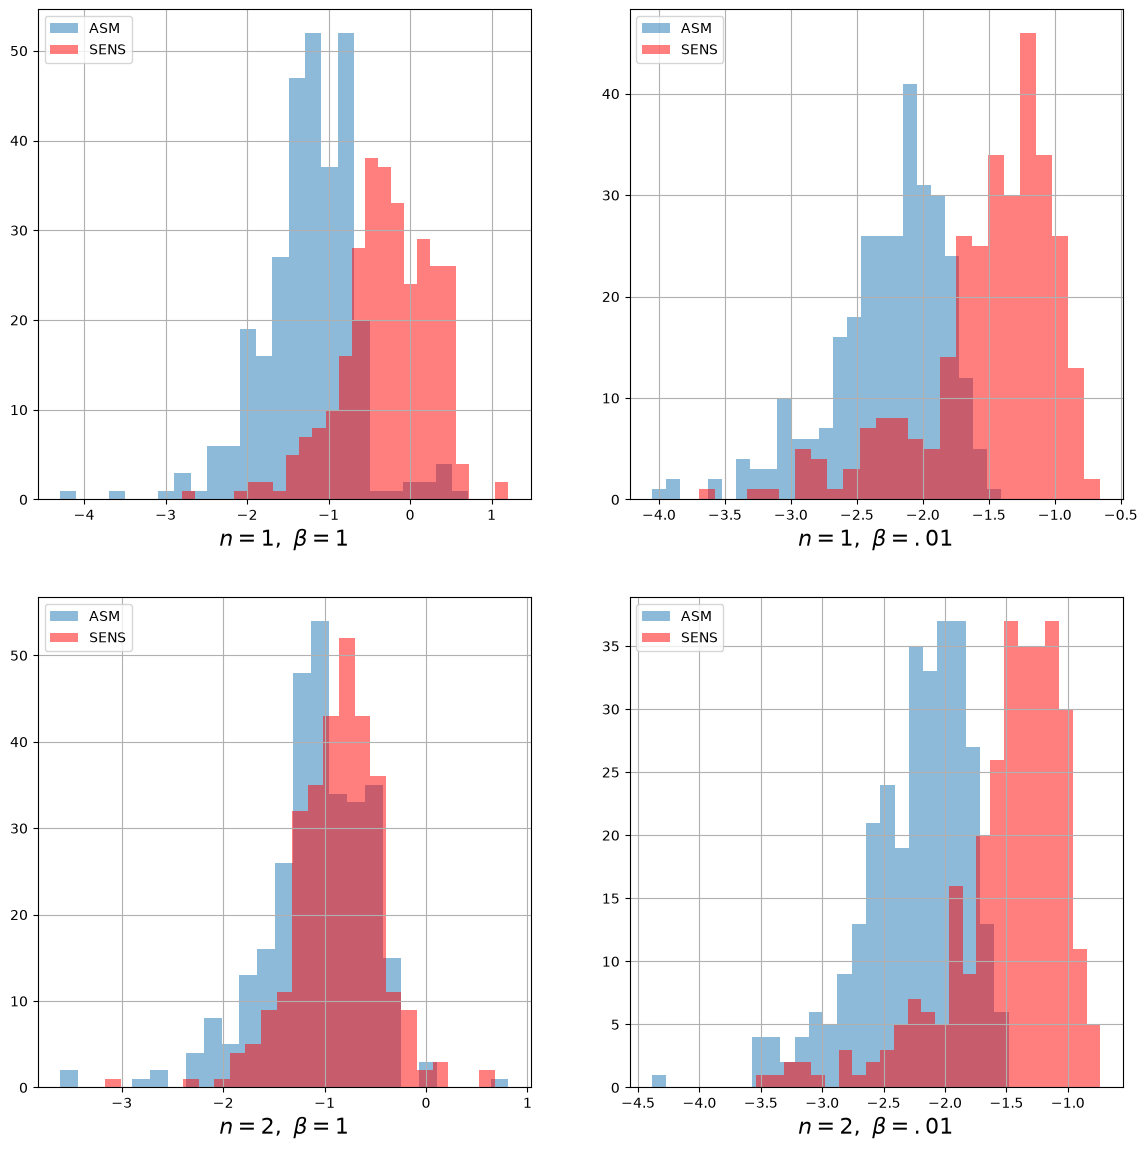

In [9]:
def rel_err(rs, X_eval, f_eval):
    return np.abs(f_eval - ac.predict(rs, X_eval)) / np.abs(f_eval)


paper_table2 = {('long', 1): 0.178, ('long', 2): 0.149, ('short', 1): 7.88e-3, ('short', 2): 7.82e-3}
err_as = {k: rel_err(rs, X, f[k[0]]) for k, rs in rs_as.items()}
err_sens = {k: rel_err(rs, X, f[k[0]]) for k, rs in rs_sens.items()}
print('mean relative error at the 300 samples')
print(f'{"":>16}{"AS":>10}{"paper AS":>10}{"SENS":>10}')
for k in rs_as:
    print(f'{"beta = " + beta[k[0]] + ", n = " + str(k[1]):>16}'
          f'{err_as[k].mean():10.2e}{paper_table2[k]:10.2e}{err_sens[k].mean():10.2e}')

fig, axes = plt.subplots(2, 2, figsize=(14, 14))
for row, n in enumerate((1, 2)):
    for col, case in enumerate(cases):
        ax = axes[row, col]
        ax.hist(np.log10(err_as[case, n]), bins=25, alpha=.5, label='ASM')
        ax.hist(np.log10(err_sens[case, n]), bins=25, color='r', alpha=.5, label='SENS')
        ax.grid(True)
        ax.legend(loc=2)
        ax.set_xlabel(rf'$n={n},\ \beta={beta[case]}$', fontsize=16)

In each case, the active subspace histogram (ASM) lies to the left of the SENS histogram, meaning the active subspace surface tends to have less error than the coordinate one. The difference is smallest for $n = 2$ and $\beta = 1$, where the second SENS coordinate captures some of the variation that the first one misses.

Lastly, we compare the active subspace kriging approximation with a kriging surface trained on the full input space, $R^{100}$, for the same cost. One adjoint gradient costs about two function evaluations, so the active subspace surface costs about $3M + P$ evaluations, and [[1]][R1] §5.3 trains the full-space surface on $3M + P$ random points: 905 for the comparison with $n = 1$ and 925 for $n = 2$. The full-space surfaces have a linear mean. All surfaces are tested on the 500 independent test points.

In [10]:
f_test = {case: np.array([s.qoi(x) for x in X_test]) for case, s in solvers.items()}
rs_full = {}
for case, s in solvers.items():
    for n, P in [(1, 5), (2, 25)]:
        X_full = rng.standard_normal((3*300 + P, 100))
        f_full = np.array([s.qoi(x) for x in X_full])
        rs_full[case, n] = ac.fit_surrogate(X=X_full, f=f_full, space=space, subspace=None,
                                            kind='rbf', degree=1)
print(f'{time.perf_counter() - t_start:.0f} s so far')

120 s so far


mean relative error at the 500 test points
                        AS      Full  Full pts
 beta = 1, n = 1  1.33e-01  9.67e-01       905
 beta = 1, n = 2  1.54e-01  7.09e-01       925
beta = .01, n = 1  8.08e-03  8.32e-03       905
beta = .01, n = 2  8.31e-03  8.09e-03       925


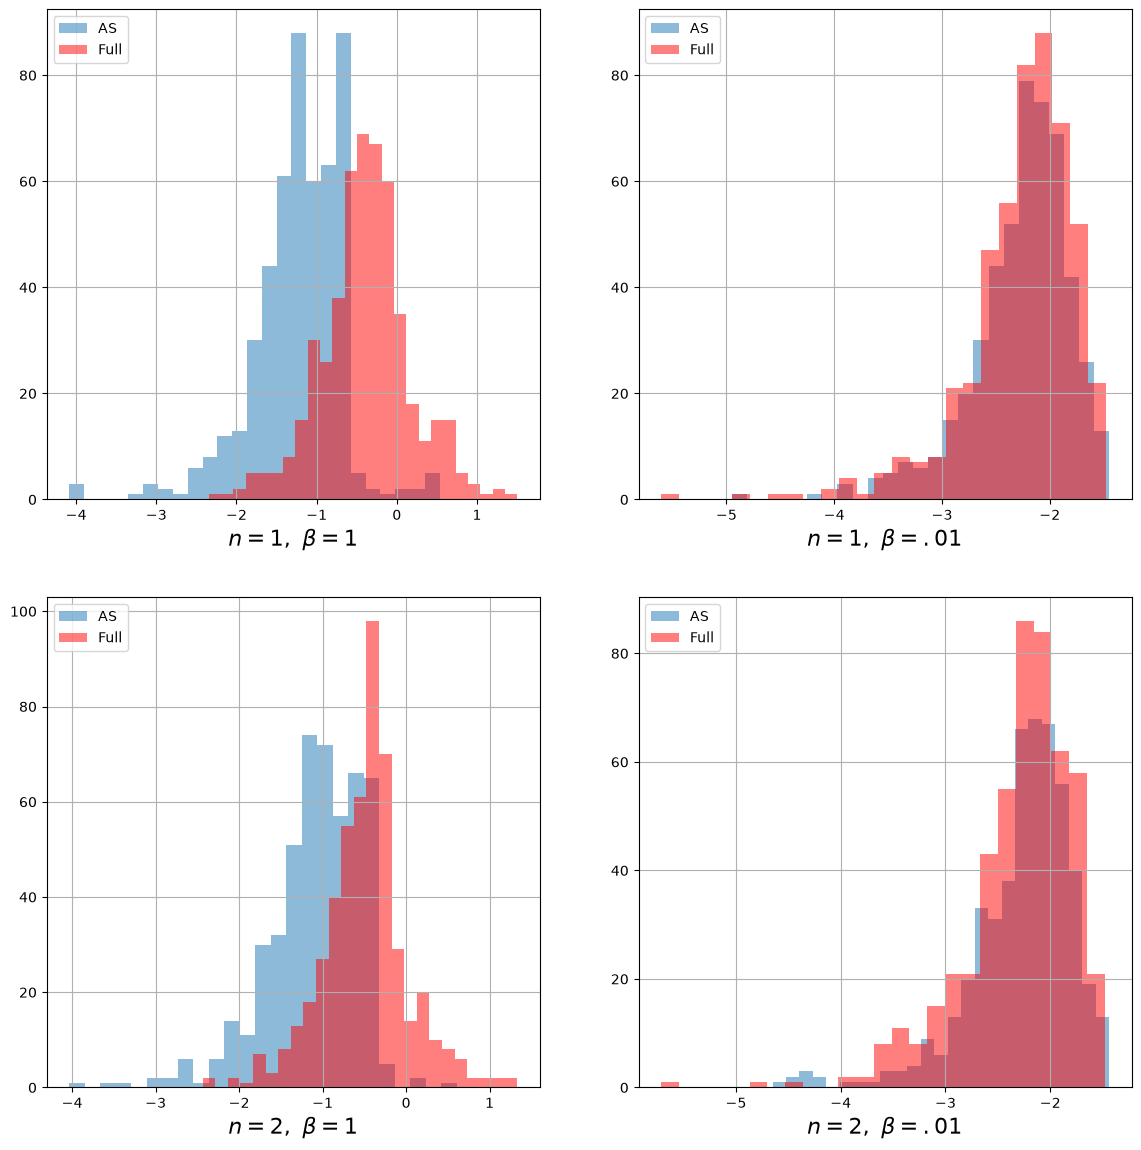

In [11]:
err_as_test = {k: rel_err(rs, X_test, f_test[k[0]]) for k, rs in rs_as.items()}
err_full = {k: rel_err(rs, X_test, f_test[k[0]]) for k, rs in rs_full.items()}
print('mean relative error at the 500 test points')
print(f'{"":>16}{"AS":>10}{"Full":>10}{"Full pts":>10}')
for k in rs_as:
    print(f'{"beta = " + beta[k[0]] + ", n = " + str(k[1]):>16}'
          f'{err_as_test[k].mean():10.2e}{err_full[k].mean():10.2e}{len(rs_full[k].f):10d}')

fig, axes = plt.subplots(2, 2, figsize=(14, 14))
for row, n in enumerate((1, 2)):
    for col, case in enumerate(cases):
        ax = axes[row, col]
        ax.hist(np.log10(err_as_test[case, n]), bins=25, alpha=.5, label='AS')
        ax.hist(np.log10(err_full[case, n]), bins=25, color='r', alpha=.5, label='Full')
        ax.grid(True)
        ax.legend(loc=2)
        ax.set_xlabel(rf'$n={n},\ \beta={beta[case]}$', fontsize=16)

For the long correlation length, the active subspace surfaces are far more accurate than the full-space surfaces of the same cost: the full-space surface's mean relative error is near 1 with 905 points and still large with 925. This agrees with [[1]][R1] Fig. 6 and with the book's Fig. 4.3 [[2]][R2]. For the short correlation length, the active subspace and full-space errors are about the same. There the quantity of interest is nearly linear in $\mathbf x$, and the full-space surface's linear mean captures it. (The 2016 notebook attributed the paper's different result for this case to a defect in the paper's kriging code; neither publication supports that, and we drop the claim.)

Overall, using active subspaces gives better approximations than the coordinate reduction from local sensitivity in every case here, and better than a full-space surface of the same cost when the function has a strongly dominant direction that is not linear, as for $\beta = 1$.

In [12]:
print(f'Total run time: {time.perf_counter() - t_start:.0f} s')

Total run time: 121 s
